# 06 — Đánh giá mô hình

Đọc kết quả đã lưu ở notebook 05, kiểm tra lại điểm và xem mô hình sai ở đâu. Không huấn luyện lại và không tạo submission.

Đặt file trong `notebooks/`, chạy từ trên xuống. Cần chạy xong 05 và giữ thư mục dự báo validation. Notebook đọc theo từng batch để giảm RAM.

Dùng các thư viện đã có ở bước trước: numpy, pandas, pyarrow, matplotlib. Các biểu đồ và bảng được lưu trong `reports/06_runs/<run_id>/`.


## 1. Chọn lần chạy

Để `RUN_ID = None` nếu muốn dùng lần chạy hoàn tất gần nhất của 05. Điền mã lần chạy nếu cần xem lại kết quả cũ. Không trộn kết quả từ nhiều lần chạy.


In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
import json, hashlib, sqlite3, tempfile
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_ID = None
BATCH_SIZE = 32768
SAMPLE_SIZE = 4000
SEED = 42
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'reports/03_config.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong thư mục dự án có reports/03_config.json.')
if RUN_ID is None:
    latest = json.loads((ROOT / 'reports/05_latest_run.json').read_text(encoding='utf-8'))
    RUN_ID = latest['run_id']
RUN_DIR = ROOT / 'reports/05_runs' / RUN_ID
PRED_DIR = ROOT / 'data/interim/05_runs' / RUN_ID
OUT = ROOT / 'reports/06_runs' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
report05 = json.loads((RUN_DIR / '05_model_training_report.json').read_text(encoding='utf-8'))
assert report05['run_id'] == RUN_ID
print('Lần chạy:', RUN_ID)
print('Kết quả lưu tại:', OUT)


Lần chạy: 20261029_225329
Kết quả lưu tại: d:\Machine-learning-project-Grocery-sales-forecast\reports\06_runs\20261029_225329


## 2. Kiểm tra nguồn dữ liệu

So khớp cấu hình và danh sách file với bước 05. Kiểm tra này không thay thế việc kiểm tra nội dung từng file Parquet. Nếu đã tạo lại feature, cần chạy lại 04 và 05 trước.


In [2]:
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

config_path = ROOT / 'reports/03_config.json'
manifest_path = ROOT / 'reports/table/03_feature_manifest.csv'
for path, key in [(config_path, 'source_config_sha256'),
                  (manifest_path, 'source_manifest_sha256')]:
    assert sha256(path) == report05[key], f'{path.name} khác lần chạy 05.'
config = json.loads(config_path.read_text(encoding='utf-8'))
manifest = pd.read_csv(manifest_path)
manifest['origin'] = pd.to_datetime(manifest.origin)
folds = config['folds']
assert len(folds) > 0
scores05 = pd.read_csv(RUN_DIR / 'scores.csv', dtype={'value': str})
assert not scores05.duplicated(['fold','experiment','predictor','group','value']).any()
assert np.isfinite(scores05.NWRMSLE).all()
print('Cấu hình và danh sách file khớp với 05.')


Cấu hình và danh sách file khớp với 05.


## 3. Cách tính điểm

NWRMSLE càng thấp càng tốt. Điểm được tính trên `log1p(doanh số)`, với trọng số 1,25 cho hàng dễ hỏng và 1 cho hàng còn lại.

Cộng tổng sai số bình phương có trọng số rồi mới lấy căn. Không lấy trung bình điểm của các batch. Baseline ở đây là `B2c_mean28`, đúng với bước 05.

Dự báo đã lưu dạng float32 nên điểm tính lại có thể lệch rất nhỏ so với 05.


In [3]:
def add_stats(acc, name, group, value, y, p, w):
    e = p - y
    z = acc[(name, group, str(value))]
    z += np.array([len(y), w.sum(), np.dot(w, e * e), np.dot(w, e)], dtype='float64')

def evaluate_file(path, fold):
    cols = ['store_nbr','item_nbr','origin','date','h','pair_status',
            'perishable','item_family','y_log','w','pred_log','baseline_log']
    pf = pq.ParquetFile(path)
    assert set(cols).issubset(pf.schema_arrow.names), f'Thiếu cột: {path.name}'
    acc = defaultdict(lambda: np.zeros(4, dtype='float64'))
    rng = np.random.default_rng(SEED)
    sample = pd.DataFrame()
    cut = pd.Timestamp(fold['valid_origin'])
    total = 0
    # Dùng ổ đĩa để kiểm tra khóa trùng giữa các batch, tránh giữ hết khóa trong RAM.
    with tempfile.TemporaryDirectory(prefix='eval06_') as tmp:
        db = sqlite3.connect(str(Path(tmp) / 'keys.sqlite'))
        try:
            db.execute('CREATE TABLE keys (s INTEGER, i INTEGER, d TEXT, PRIMARY KEY(s,i,d)) WITHOUT ROWID')
            for batch in pf.iter_batches(batch_size=BATCH_SIZE, columns=cols):
                d = batch.to_pandas()
                assert not d[cols].isna().any().any(), f'Có giá trị thiếu: {path.name}'
                d['origin'] = pd.to_datetime(d.origin)
                d['date'] = pd.to_datetime(d.date)
                assert (d.origin == cut).all()
                assert ((d.date - d.origin).dt.days == d.h).all()
                assert d.h.between(1, int(config['horizon'])).all()
                assert d.pair_status.isin([0,1,2,3]).all()
                assert d.perishable.isin([0,1]).all()
                for col in ['store_nbr','item_nbr','h','pair_status']:
                    assert np.isfinite(d[col]).all() and (d[col] == np.floor(d[col])).all()
                keys = zip(d.store_nbr.astype(int), d.item_nbr.astype(int), d.date.astype(str))
                try:
                    db.executemany('INSERT INTO keys VALUES (?,?,?)', keys)
                except sqlite3.IntegrityError as exc:
                    raise AssertionError(f'Trùng khóa cửa hàng, mặt hàng, ngày: {path.name}') from exc
                db.commit()
                y = d.y_log.to_numpy(dtype='float64')
                w = d.w.to_numpy(dtype='float64')
                assert np.isfinite(y).all() and (y >= 0).all()
                assert np.isfinite(w).all() and (w > 0).all()
                assert np.allclose(w, np.where(d.perishable == 1, 1.25, 1.0))
                for name, col in [('model','pred_log'), ('B2c_mean28','baseline_log')]:
                    p = d[col].to_numpy(dtype='float64')
                    assert np.isfinite(p).all() and (p >= 0).all()
                    add_stats(acc, name, 'overall', 'all', y, p, w)
                    for group in ['h','pair_status','perishable','item_family']:
                        for value, index in d.groupby(group, observed=True).indices.items():
                            add_stats(acc, name, group, int(value), y[index], p[index], w[index])
                d['_random'] = rng.random(len(d))
                sample = pd.concat([sample, d], ignore_index=True).nsmallest(SAMPLE_SIZE, '_random')
                total += len(d)
        finally:
            db.close()
    expected = manifest[(manifest.role == fold['valid_role']) & (manifest.origin == cut)]
    assert len(expected) == 1 and total == int(expected.rows.iloc[0]) and total > 0
    rows = []
    for (predictor, group, value), (n, sw, sse, se) in acc.items():
        rows.append(dict(predictor=predictor, group=group, value=value, rows=int(n),
                         weight_sum=sw, weighted_sse=sse, NWRMSLE=np.sqrt(sse/sw), bias_log=se/sw))
    return pd.DataFrame(rows), sample.drop(columns='_random')


## 4. Tính lại điểm từ dự báo

Bắt buộc có dự báo `safe` cho từng fold. Nếu 05 đã lưu dự báo Ridge hoặc Extra Trees thì chúng cũng được đánh giá. Cấu hình chỉ có bảng điểm mà chưa lưu dự báo vẫn xuất hiện ở bảng so sánh, nhưng chưa được tính lại điểm tại đây.


In [4]:
evaluated = []
samples = {}
checks = []
prediction_hashes = {}
for fold in folds:
    fold_name = fold['fold']
    experiments = scores05.loc[scores05.fold == fold_name, 'experiment'].unique()
    assert 'safe' in experiments, f'Thiếu safe ở {fold_name}'
    for exp in experiments:
        path = PRED_DIR / f'{fold_name}_{exp}.parquet'
        if not path.exists():
            assert exp != 'safe', f'Thiếu {path}. Chạy 05 với SAVE_SAFE_VALID_PREDICTIONS=True.'
            print('Chưa có file dự báo:', fold_name, exp)
            continue
        table, sample = evaluate_file(path, fold)
        table['fold'] = fold_name
        table['experiment'] = exp
        ref = scores05[(scores05.fold == fold_name) & (scores05.experiment == exp)]
        merged = table.merge(ref, on=['predictor','group','value'], suffixes=('_06','_05'), validate='one_to_one')
        assert len(merged) == len(table) == len(ref), 'Nhóm đánh giá khác 05.'
        assert np.array_equal(merged.rows_06, merged.rows_05)
        assert np.allclose(merged.weight_sum_06, merged.weight_sum_05, rtol=1e-8, atol=1e-6)
        assert np.allclose(merged.NWRMSLE_06, merged.NWRMSLE_05, rtol=1e-5, atol=1e-6), 'Điểm khác 05.'
        checks.append(dict(fold=fold_name, experiment=exp, status='OK',
                           max_score_difference=float(abs(merged.NWRMSLE_06-merged.NWRMSLE_05).max())))
        prediction_hashes[path.name] = sha256(path)
        evaluated.append(table)
        samples[(fold_name, exp)] = sample
metrics = pd.concat(evaluated, ignore_index=True)
checks = pd.DataFrame(checks)
metrics.to_csv(OUT / '06_metrics.csv', index=False)
checks.to_csv(OUT / '06_validation_checks.csv', index=False)
display(checks)


,fold,experiment,status,max_score_difference
0,V1_last16,safe,OK,7.857638e-10
1,V1_last16,plus_future_promo,OK,6.135460e-10
2,V1_last16,plus_oil,OK,8.814558e-10
3,V1_last16,linear_safe,OK,5.958956e-10
4,V1_last16,ridge_safe,OK,7.141528e-10
5,V1_last16,extratrees_safe,OK,8.064063e-10
6,V2_seasonal,safe,OK,6.262943e-10
7,V2_seasonal,plus_future_promo,OK,1.188150e-09
8,V2_seasonal,plus_oil,OK,6.608042e-10
9,V2_seasonal,linear_safe,OK,8.366455e-10


Cả 12 tổ hợp cấu hình–fold đều có kết quả kiểm tra OK. Sai khác lớn nhất giữa điểm tính lại và điểm ở notebook 05 khoảng 1,53 × 10⁻⁹, không ảnh hưởng đến kết quả so sánh.

Các file dự báo đã qua kiểm tra khóa trùng, số dòng, ngày dự báo, nhãn và trọng số. Kết quả này xác nhận sự nhất quán giữa dự báo đã lưu và bảng điểm; chưa chứng minh toàn bộ quá trình tạo feature không có rò rỉ dữ liệu.

## 5. So sánh với baseline

Mức cải thiện dương nghĩa là mô hình có điểm thấp hơn baseline. Xem riêng từng fold để tránh che mất giai đoạn mô hình hoạt động kém. Các biến thể khuyến mãi hoặc dầu của LightGBM không phải là thuật toán khác.


predictor,fold,experiment,B2c_mean28,model,improvement_pct,recomputed_06
0,V1_last16,extratrees_safe,0.638588,0.613622,3.909571,True
1,V1_last16,linear_safe,0.638588,0.619748,2.950165,True
2,V1_last16,plus_future_promo,0.638588,0.591451,7.381430,True
3,V1_last16,plus_oil,0.638588,0.614332,3.798309,True
4,V1_last16,ridge_safe,0.638588,0.619208,3.034757,True
5,V1_last16,safe,0.638588,0.614003,3.849894,True
6,V2_seasonal,extratrees_safe,0.607533,0.585308,3.658308,True
7,V2_seasonal,linear_safe,0.607533,0.587940,3.225107,True
8,V2_seasonal,plus_future_promo,0.607533,0.571574,5.918847,True
9,V2_seasonal,plus_oil,0.607533,0.586539,3.455626,True


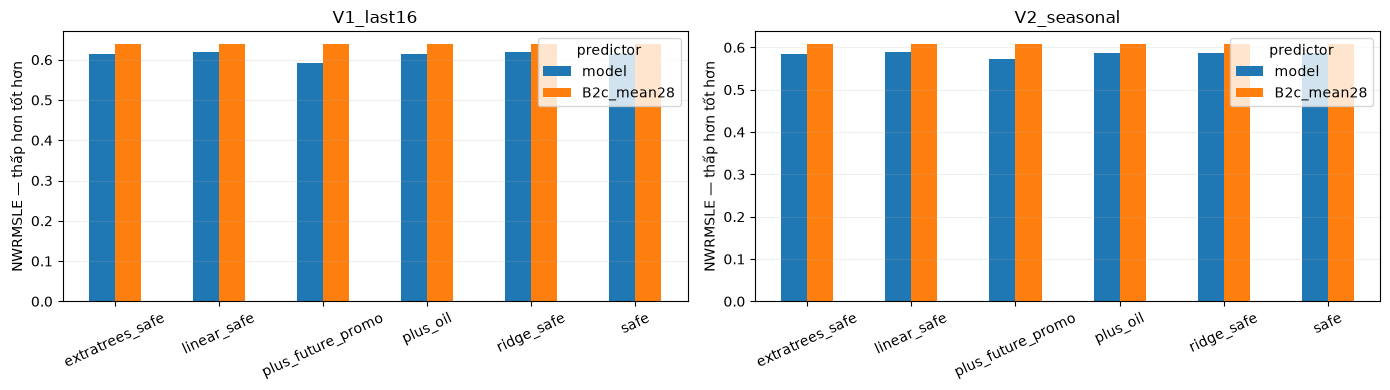

In [5]:
comparison = scores05[scores05.group == 'overall'].pivot(
    index=['fold','experiment'], columns='predictor', values='NWRMSLE').reset_index()
comparison['improvement_pct'] = 100 * (comparison.B2c_mean28 - comparison.model) / comparison.B2c_mean28
verified = set(zip(checks.fold, checks.experiment))
comparison['recomputed_06'] = [(f,e) in verified for f,e in zip(comparison.fold, comparison.experiment)]
comparison.to_csv(OUT / '06_comparison.csv', index=False)
display(comparison.round(6))
fig, axes = plt.subplots(1, len(folds), figsize=(7*len(folds), 4), squeeze=False)
for ax, fold in zip(axes[0], folds):
    d = comparison[comparison.fold == fold['fold']].set_index('experiment')
    d[['model','B2c_mean28']].plot.bar(ax=ax, rot=25)
    ax.set(title=fold['fold'], ylabel='NWRMSLE — thấp hơn tốt hơn', xlabel='')
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(OUT / '06_model_comparison.png', dpi=150)
plt.show()


Tất cả các phương án đều có NWRMSLE thấp hơn baseline trên cả hai fold.

| Phương án | V1 | V2 | Giảm lỗi so với baseline V1 / V2 |
|---|---:|---:|---:|
| Baseline mean28 | 0,638588 | 0,607533 | — |
| Linear Regression | 0,619748 | 0,587940 | 2,95% / 3,23% |
| Ridge | 0,619208 | 0,587618 | 3,03% / 3,28% |
| ExtraTrees | 0,613622 | 0,585308 | 3,91% / 3,66% |
| LightGBM safe | 0,614003 | 0,586527 | 3,85% / 3,46% |
| LightGBM thêm dầu | 0,614332 | 0,586539 | 3,80% / 3,46% |
| LightGBM thêm khuyến mãi tương lai | 0,591451 | 0,571574 | 7,38% / 5,92% |

ExtraTrees đạt điểm tốt nhất trong các phương án không dùng khuyến mãi tương lai. Tuy nhiên, chênh lệch với LightGBM safe chỉ khoảng 0,000381 ở V1 và 0,001219 ở V2. Cần thử thêm mẫu học hoặc seed trước khi kết luận ưu thế này ổn định. Các thuật toán hiện cũng dùng giới hạn số dòng học khác nhau.

Ridge cải thiện nhẹ so với Linear Regression trên cả hai fold. Thêm giá dầu không cải thiện LightGBM trong lần thử này.

Khuyến mãi tương lai cho điểm thấp nhất, nhưng cách ghi nhận khuyến mãi trong train và test khác nhau. Ở train, trạng thái này được quan sát qua các dòng bán; vì vậy mức cải thiện trên validation chưa đủ để khẳng định chất lượng trên test.

V2 có điểm thấp hơn V1 ở tất cả phương án, kể cả baseline. Hai fold khác thời điểm và cơ cấu dữ liệu, nên không thể quy chênh lệch này riêng cho khả năng học của mô hình.

## 6. Sai số theo ngày dự báo

`h = 1` là ngày sau mốc dự báo; `h = 16` là ngày xa nhất. Đường mô hình nằm trên baseline nghĩa là mô hình kém hơn ở ngày đó.


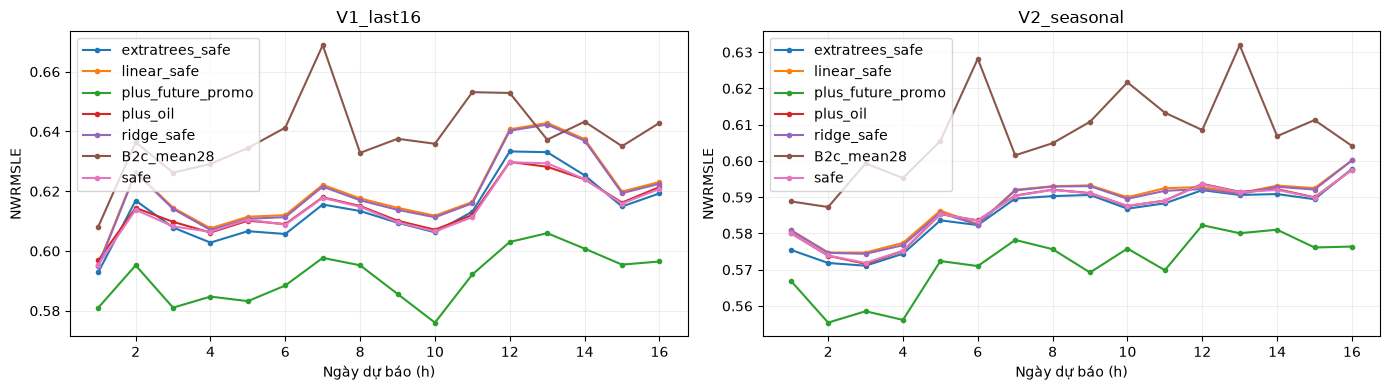

In [6]:
fig, axes = plt.subplots(1, len(folds), figsize=(7*len(folds), 4), squeeze=False)
for ax, fold in zip(axes[0], folds):
    d = metrics[(metrics.fold == fold['fold']) & (metrics.group == 'h')].copy()
    d['h'] = d.value.astype(int)
    for (exp, predictor), g in d.groupby(['experiment','predictor']):
        if predictor == 'B2c_mean28' and exp != 'safe':
            continue
        g = g.sort_values('h')
        ax.plot(g.h, g.NWRMSLE, marker='.', label=exp if predictor == 'model' else predictor)
    ax.set(title=fold['fold'], xlabel='Ngày dự báo (h)', ylabel='NWRMSLE')
    ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT / '06_horizon.png', dpi=150)
plt.show()


Trên biểu đồ, các phương án học máy có sai số thấp hơn baseline ở cả 16 bước dự báo trên hai fold. Các đường Linear Regression, Ridge, ExtraTrees và LightGBM safe khá gần nhau; phương án thêm khuyến mãi tương lai thấp hơn rõ hơn.

Sai số không tăng đều theo khoảng cách dự báo. Ở V1, nhóm mô hình safe tăng lỗi quanh h = 12–14 rồi giảm tại h = 15. Ở V2, lỗi nhìn chung cao hơn ở phần cuối horizon nhưng vẫn có dao động giữa các ngày.

Mỗi giá trị h trong một fold tương ứng với một ngày cụ thể. Vì vậy, biến động trên biểu đồ có thể liên quan cả khoảng cách dự báo và đặc điểm của ngày đó. Hai fold hiện chưa đủ để tách riêng hai ảnh hưởng này.

## 7. Nhóm nào còn dự báo kém?

Nhóm 0 có bán trong 28 ngày gần nhất. Nhóm 1 có lịch sử nhưng không có bán dương trong cửa sổ đó. Nhóm 2 là cặp cửa hàng–mặt hàng mới; nhóm 3 là mặt hàng mới.

`bias_log` dương: thường dự báo cao; âm: thường dự báo thấp. Đây là chênh lệch trên thang log, không phải số lượng sản phẩm.

Bảng nhóm hàng giữ mã `item_family` như bước 03. Nhóm có tổng sai số lớn đáng ưu tiên xem xét, nhưng không nhất thiết có điểm trung bình cao nhất.


In [7]:
safe = metrics[metrics.experiment == 'safe']
for group in ['pair_status','perishable']:
    display(safe[safe.group == group][['fold','predictor','value','rows','weight_sum','NWRMSLE','bias_log']].round(6))
family = safe[(safe.group == 'item_family') & (safe.predictor == 'model')].copy()
family['error_share'] = family.weighted_sse / family.groupby('fold').weighted_sse.transform('sum').replace(0, np.nan)
for fold in folds:
    print(fold['fold'])
    display(family[family.fold == fold['fold']].nlargest(10, 'weighted_sse')[
        ['value','rows','NWRMSLE','bias_log','error_share']].round(6))
family.to_csv(OUT / '06_family_errors.csv', index=False)


,fold,predictor,value,rows,weight_sum,NWRMSLE,bias_log
2,V1_last16,model,0,2409184,2542664.0,0.655783,0.009317
3,V1_last16,model,1,377056,401584.0,0.202722,0.028025
41,V1_last16,B2c_mean28,0,2409184,2542664.0,0.682718,0.010484
42,V1_last16,B2c_mean28,1,377056,401584.0,0.196470,-0.023203
650,V2_seasonal,model,0,1063198,1122221.5,0.611441,-0.015721
651,V2_seasonal,model,1,108932,117229.0,0.241443,0.025690
688,V2_seasonal,B2c_mean28,0,1063198,1122221.5,0.633751,0.015315
689,V2_seasonal,B2c_mean28,1,108932,117229.0,0.239932,-0.036603


,fold,predictor,value,rows,weight_sum,NWRMSLE,bias_log
4,V1_last16,model,0,2154208,2154208.0,0.613252,0.008907
5,V1_last16,model,1,632032,790040.0,0.616047,0.019946
43,V1_last16,B2c_mean28,0,2154208,2154208.0,0.637117,0.002937
44,V1_last16,B2c_mean28,1,632032,790040.0,0.642582,0.013941
652,V2_seasonal,model,0,902848,902848.0,0.586271,-0.009200
653,V2_seasonal,model,1,269282,336602.5,0.587215,-0.018788
690,V2_seasonal,B2c_mean28,0,902848,902848.0,0.605787,0.015321
691,V2_seasonal,B2c_mean28,1,269282,336602.5,0.612194,-0.002782


V1_last16


,value,rows,NWRMSLE,bias_log,error_share
18,12,894384,0.616310,0.006674,0.306060
9,3,455328,0.701002,0.007223,0.201580
13,7,310704,0.610596,0.007753,0.104361
36,30,192144,0.660745,0.003809,0.094469
14,8,172192,0.580823,0.024921,0.065418
11,5,80656,0.649437,0.022136,0.038309
31,25,110768,0.521028,0.002667,0.027091
24,18,79024,0.593552,0.064006,0.025082
15,9,66272,0.577094,0.045670,0.024855
34,28,35664,0.699704,0.038065,0.019663


V2_seasonal


,value,rows,NWRMSLE,bias_log,error_share
665,12,387054,0.580708,-0.004407,0.306113
657,3,171974,0.699860,-0.007850,0.197551
660,7,138324,0.569946,-0.027628,0.105380
683,30,81288,0.611454,-0.010551,0.089096
661,8,70854,0.559593,-0.027922,0.065045
658,5,36720,0.601348,-0.025131,0.038928
678,25,48000,0.508439,-0.011848,0.029101
662,9,29642,0.542213,-0.008919,0.025548
671,18,33034,0.528915,0.003548,0.021673
681,28,15284,0.676028,-0.007753,0.020477


LightGBM safe cải thiện dự báo cho các cặp có bán trong 28 ngày gần nhất, nhưng chưa tốt hơn baseline đối với các cặp không bán dương trong cửa sổ này.

| Nhóm cặp | Baseline V1 | Model V1 | Baseline V2 | Model V2 |
|---|---:|---:|---:|---:|
| Có bán gần đây | 0,682718 | 0,655783 | 0,633751 | 0,611441 |
| Không bán gần đây | 0,196470 | 0,202722 | 0,239932 | 0,241443 |

Ở nhóm không bán gần đây, bias_log của mô hình dương trên cả hai fold: khoảng 0,0280 ở V1 và 0,0257 ở V2. Mô hình có xu hướng dự báo cao hơn thực tế trung bình trên thang log. Baseline có bias âm nhưng vẫn đạt NWRMSLE thấp hơn. Do đó, bias gần 0 hơn chưa chắc đồng nghĩa với sai số tổng thể thấp hơn.

Theo tính mau hỏng, mô hình vượt baseline ở cả hai nhóm. NWRMSLE của hàng mau hỏng hơi cao hơn hàng thường: 0,616047 so với 0,613252 ở V1 và 0,587215 so với 0,586271 ở V2. Chênh lệch này nhỏ trong lần đánh giá hiện tại.

Theo nhóm hàng, bốn mã 12, 3, 7 và 30 đóng góp khoảng 70,65% tổng sai số bình phương có trọng số ở V1 và 69,81% ở V2. Đây là các nhóm nên ưu tiên xem xét khi muốn giảm lỗi toàn bộ tập.

Mã 12 đóng góp nhiều lỗi nhất, khoảng 30,61% ở mỗi fold, đồng thời có số dòng lớn nhất trong bảng. Mã 3 có NWRMSLE khoảng 0,70 và đóng góp gần 20% lỗi. Cần phân biệt nhóm có nhiều lỗi do quy mô lớn với nhóm có sai số trung bình cao. Tên nhóm hàng cần được đối chiếu từ 03_encodings.json.

## 8. Giá trị thực tế và dự báo

Biểu đồ dùng mẫu ngẫu nhiên tối đa 4.000 dòng mỗi file; điểm số ở trên dùng toàn bộ validation. Không dùng mẫu biểu đồ để tính điểm thay thế.

Ở hình trái, điểm càng sát đường chéo càng tốt. Ở hình phải, sai số bằng dự báo trừ thực tế; đường 0 là dự báo đúng. Cả hai hình dùng thang `log1p` để nhìn rõ cả doanh số nhỏ và lớn.


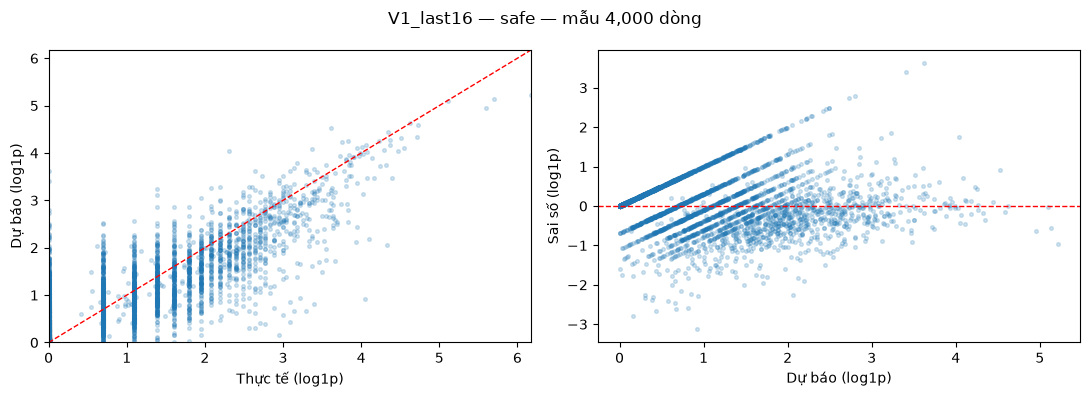

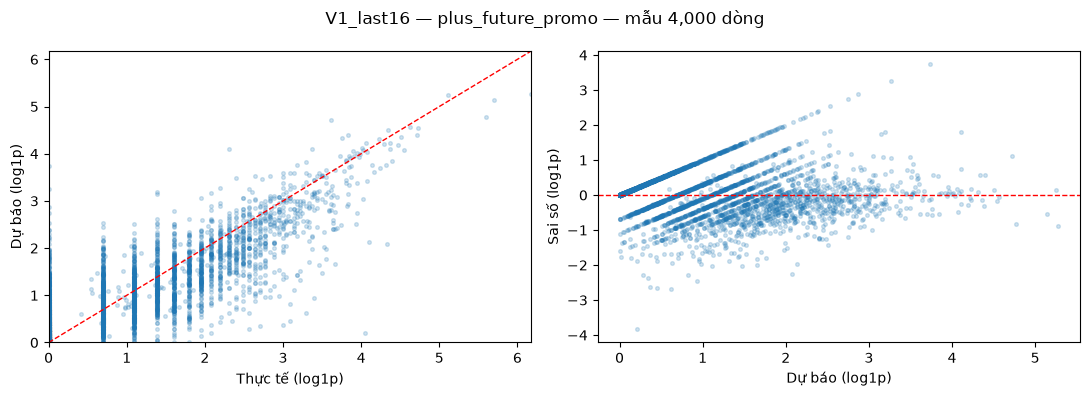

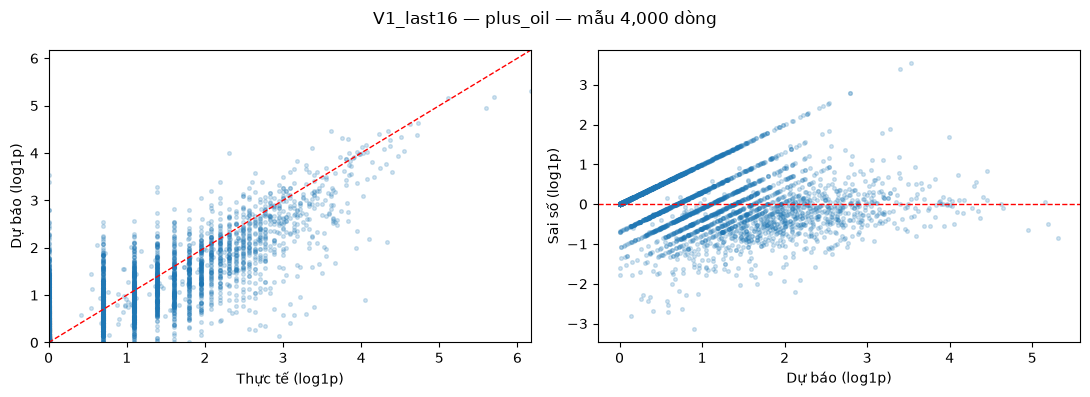

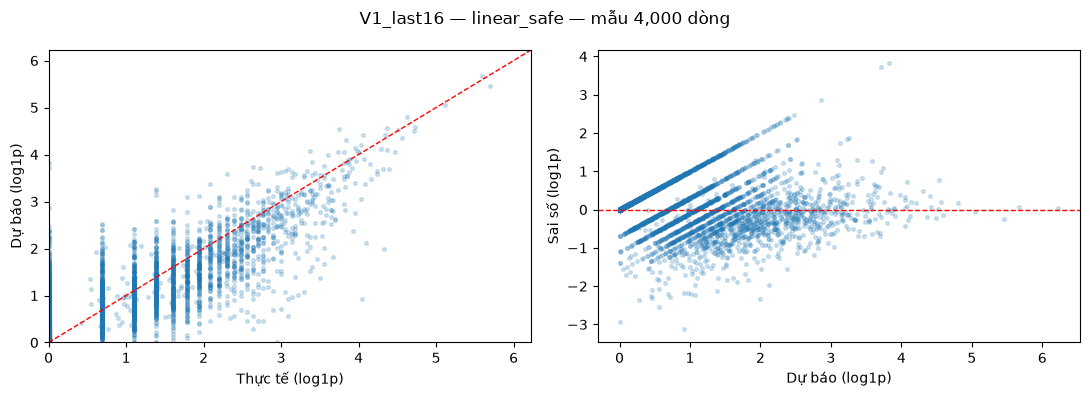

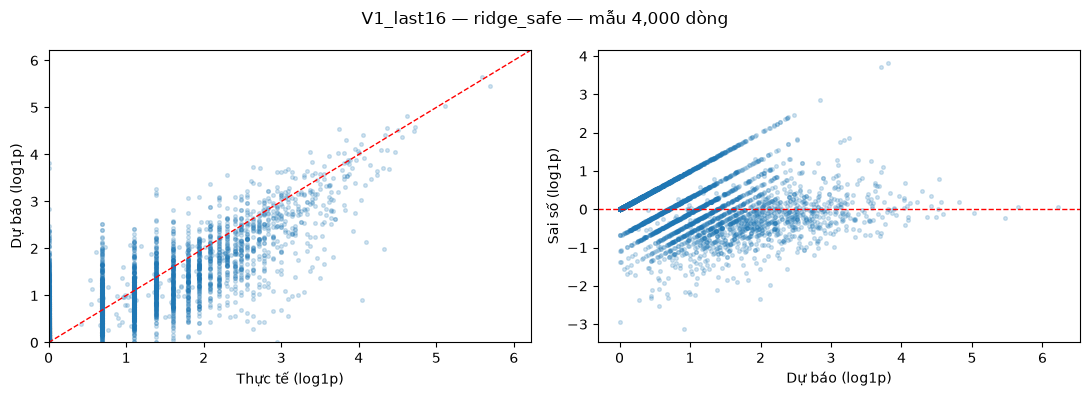

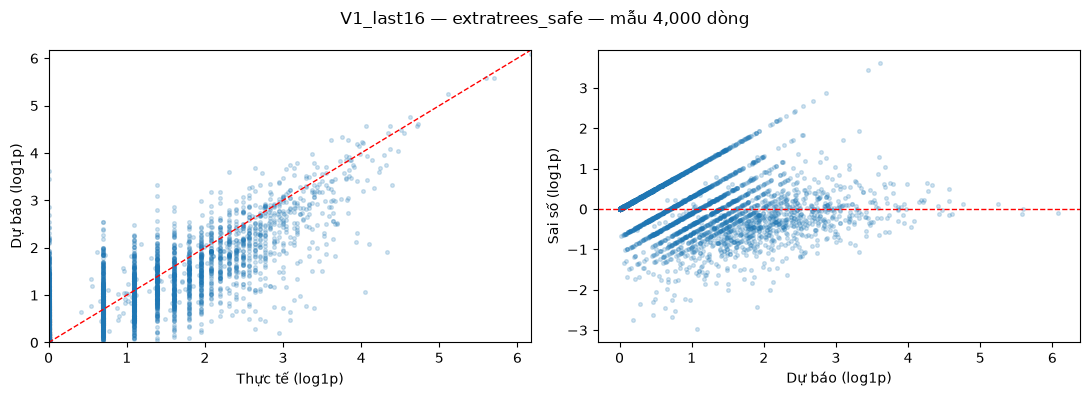

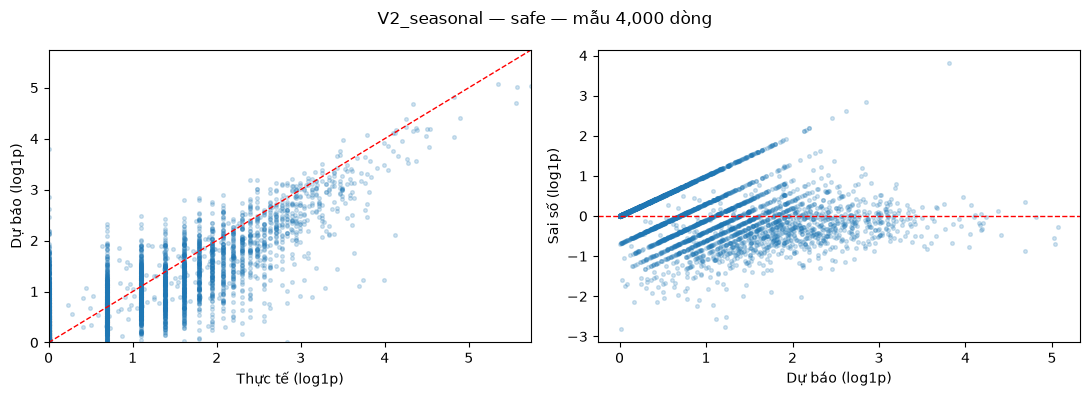

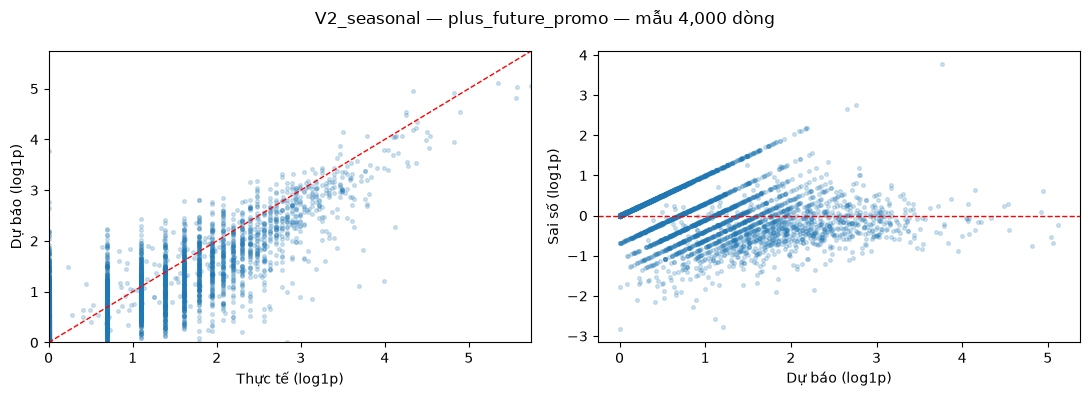

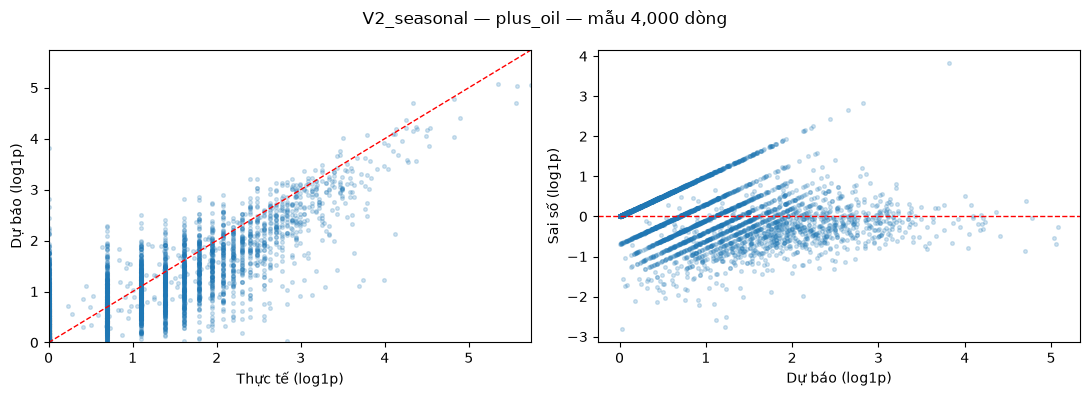

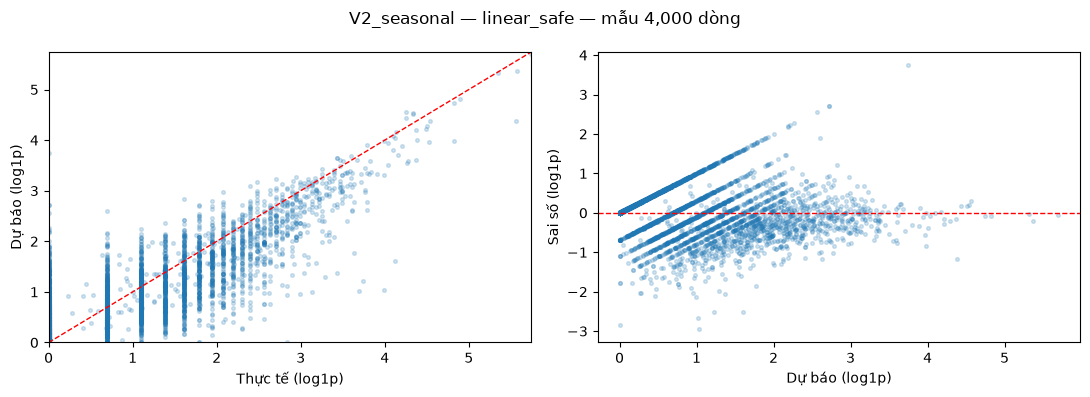

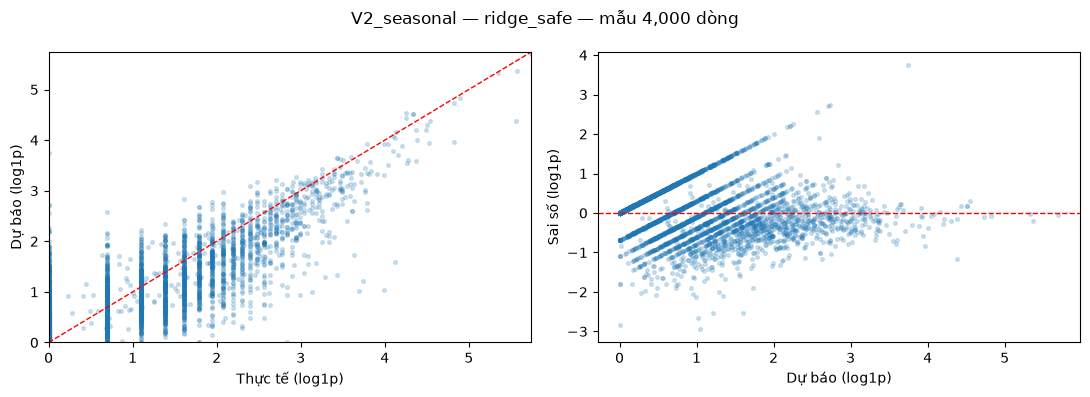

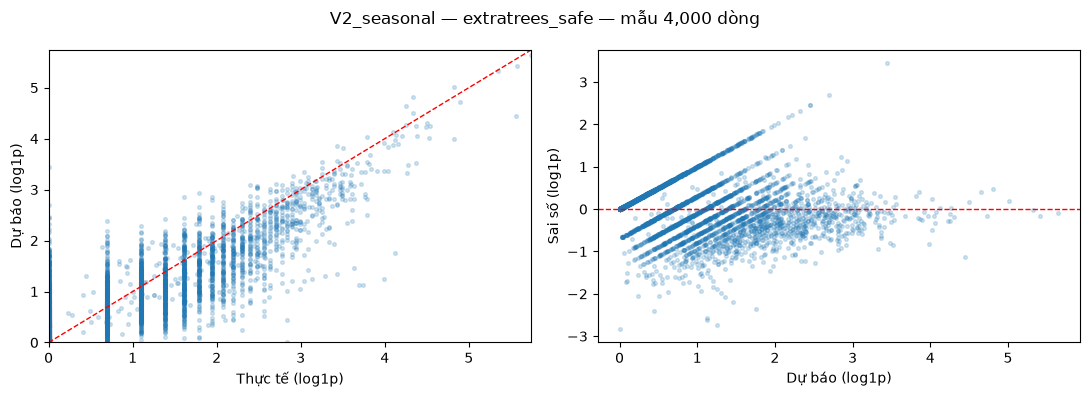

In [8]:
for (fold_name, exp), d in samples.items():
    fig, axes = plt.subplots(1, 2, figsize=(11,4))
    top = max(float(d.y_log.max()), float(d.pred_log.max()), 1.)
    axes[0].scatter(d.y_log, d.pred_log, s=7, alpha=.2)
    axes[0].plot([0,top], [0,top], 'r--', linewidth=1)
    axes[0].set(xlabel='Thực tế (log1p)', ylabel='Dự báo (log1p)', xlim=(0,top), ylim=(0,top))
    axes[1].scatter(d.pred_log, d.pred_log-d.y_log, s=7, alpha=.2)
    axes[1].axhline(0, color='r', linestyle='--', linewidth=1)
    axes[1].set(xlabel='Dự báo (log1p)', ylabel='Sai số (log1p)')
    fig.suptitle(f'{fold_name} — {exp} — mẫu {len(d):,} dòng')
    fig.tight_layout()
    fig.savefig(OUT / f'06_scatter_residual_{fold_name}_{exp}.png', dpi=150)
    plt.show()


Các biểu đồ dùng mẫu 4.000 dòng cho mỗi cấu hình–fold. Dự báo nhìn chung tăng theo giá trị thực tế, nhưng các điểm vẫn phân tán quanh đường chéo.

Ở vùng doanh số thực tế cao, nhiều điểm nằm dưới đường chéo, cho thấy mô hình còn dự báo thấp ở một số trường hợp bán mạnh. Với các dòng có doanh số thực tế bằng 0, vẫn xuất hiện dự báo dương.

Các dải thẳng đứng trong scatter và dải chéo trong biểu đồ phần dư phù hợp với việc nhiều dòng có cùng giá trị doanh số. Với một giá trị thực tế cố định, phần dư bằng dự báo trừ giá trị đó nên tạo thành đường chéo. Hình dạng này tự nó không chứng minh mô hình bị lỗi.

Các phương án có hình phân bố khá giống nhau; chênh lệch nhỏ giữa ExtraTrees và LightGBM khó nhận biết chỉ bằng mắt. Bảng NWRMSLE trên toàn bộ validation là căn cứ chính để so sánh. Các điểm lệch xa trong mẫu gợi ý cần xem thêm lịch sử từng cặp và thời điểm phát sinh sai số.

## 9. Kết quả này áp dụng đến đâu?

Validation có thể chỉ chứa nhóm đã có lịch sử. Khi đó chưa biết cách dự báo dự phòng cho nhóm mới tốt hay kém. Không suy điểm của toàn bộ test từ điểm của nhóm đã có lịch sử.

V1 và V2 đã dùng để so sánh mô hình, nên không còn là tập kiểm tra hoàn toàn độc lập. Điểm tốt hơn trên hai fold chưa chứng minh mọi giai đoạn đều tốt hơn.


In [9]:
coverage = safe[(safe.group == 'pair_status') & (safe.predictor == 'model')].copy()
coverage['weight_share'] = coverage.weight_sum / coverage.groupby('fold').weight_sum.transform('sum')
display(coverage[['fold','value','rows','weight_share','NWRMSLE']].round(6))
coverage.to_csv(OUT / '06_validation_coverage.csv', index=False)
final_info = report05.get('final_model', {})
test_counts = final_info.get('test_rows_by_status', {})
if test_counts:
    test_coverage = pd.DataFrame([{'pair_status':int(k), 'rows':int(v)} for k,v in test_counts.items()])
    test_coverage['row_share'] = test_coverage.rows / test_coverage.rows.sum()
    display(test_coverage.sort_values('pair_status'))
    test_coverage.to_csv(OUT / '06_test_row_coverage.csv', index=False)
    print('Tỷ lệ trên là tỷ lệ dòng test, không phải tỷ lệ trọng số hay điểm test.')
else:
    print('05 chưa lưu số dòng test theo nhóm; chưa tính được độ phủ test tại đây.')
print('Dự báo test hữu hạn chỉ xác nhận chạy được, không xác nhận dự báo đúng.')


,fold,value,rows,weight_share,NWRMSLE
2,V1_last16,0,2409184,0.863604,0.655783
3,V1_last16,1,377056,0.136396,0.202722
650,V2_seasonal,0,1063198,0.905419,0.611441
651,V2_seasonal,1,108932,0.094581,0.241443


,pair_status,rows,row_share
0,0,2395264,0.710663
2,1,264144,0.078370
1,2,659216,0.195586
3,3,51840,0.015381


Tỷ lệ trên là tỷ lệ dòng test, không phải tỷ lệ trọng số hay điểm test.
Dự báo test hữu hạn chỉ xác nhận chạy được, không xác nhận dự báo đúng.


Validation hiện chỉ gồm các cặp đã có lịch sử. Nhóm có bán gần đây chiếm 86,36% tổng trọng số ở V1 và 90,54% ở V2; phần còn lại là các cặp không bán gần đây.

Trong test, cặp mới của item đã biết có 659.216 dòng, còn item mới có 51.840 dòng. Tổng cộng 711.056 dòng, tương đương 21,10% test, thuộc các nhóm chưa được đánh giá trên validation hiện tại.

Vì vậy, điểm V1/V2 chưa phản ánh chất lượng của toàn bộ luồng dự báo test, đặc biệt là các nhánh dự báo dự phòng cho cặp mới. Kiểm tra dự báo hữu hạn chỉ xác nhận chương trình tạo được kết quả hợp lệ về số học.

V1 và V2 đã được dùng để so sánh phương án nên không còn là tập kiểm tra độc lập với quá trình lựa chọn mô hình.

## 10. Nhận xét và bước tiếp theo

Kết quả đánh giá đã khớp với notebook 05. LightGBM safe giảm NWRMSLE so với baseline khoảng 3,85% ở V1 và 3,46% ở V2. ExtraTrees có điểm thấp hơn nhẹ trên cả hai fold và là phương án cần tiếp tục so sánh.

Hạn chế rõ nhất là mô hình safe còn kém baseline ở nhóm không bán gần đây, trong khi nhóm cặp mới chiếm 21,10% test chưa được đánh giá. Phương án dùng khuyến mãi tương lai có điểm tốt nhất nhưng vẫn cần kiểm chứng ảnh hưởng của cách ghi nhận dữ liệu.

Các bước tiếp theo:

1. Giữ lần chạy này làm mốc so sánh cho các thử nghiệm sau.
2. Thử tăng số dòng học, giữ nguyên feature và tham số để đo riêng tác động của lượng dữ liệu.
3. So sánh có và không có nhóm feature ngày lễ; thử thêm thống kê theo cửa hàng–class.
4. Thử kết hợp dự báo LightGBM và ExtraTrees trên cùng các khóa validation.
5. Đánh giá thêm cặp mới và xem đường thực tế–dự báo của những cặp có lỗi lớn.

Có thể viết phần tổng hợp kết quả hiện tại ở notebook 07. Việc chọn mô hình cuối nên thực hiện sau khi hoàn thành các thử nghiệm đã chọn và nêu rõ phạm vi mà kết quả đánh giá bao phủ.

In [10]:
safe_comparison = comparison[comparison.experiment == 'safe']
assert len(safe_comparison) == len(folds)
better_all = bool((safe_comparison.improvement_pct > 0).all())
lines = [f'# Đánh giá mô hình — {RUN_ID}', '',
         'Đã kiểm tra khóa trùng, số dòng, ngày dự báo, trọng số và điểm tính lại.', '']
for row in safe_comparison.itertuples():
    lines.append(f'- {row.fold}: safe {row.model:.6f}; baseline {row.B2c_mean28:.6f}; cải thiện {row.improvement_pct:.2f}%.')
lines += ['', 'Mô hình safe tốt hơn baseline trên mọi fold.' if better_all else
          'Mô hình safe chưa tốt hơn baseline trên mọi fold. Cần xem lại 05 trước khi chốt mô hình.']
status_scores = safe[safe.group == 'pair_status'].pivot(index=['fold','value'], columns='predictor', values='NWRMSLE')
for (fold_name, value), row in status_scores.iterrows():
    if row['model'] > row['B2c_mean28']:
        lines.append(f'- {fold_name}, nhóm {value}: mô hình kém baseline; cần xem kỹ nhóm này.')
missing_cold = [f['fold'] for f in folds if not {'2','3'}.issubset(
    set(coverage.loc[coverage.fold == f['fold'], 'value']))]
if missing_cold:
    lines += ['', 'Chưa đánh giá đủ nhóm cặp mới và mặt hàng mới ở: ' + ', '.join(missing_cold) + '.']
lines += ['', 'Chưa có điểm test. Hai fold đã dùng để so sánh mô hình; không phải kiểm tra độc lập.',
          'Chưa thử đầy đủ cách xử lý ngày không có dòng. Khuyến mãi tương lai vẫn cần kiểm chứng.', '',
          'Có thể viết 07 để tổng hợp kết quả và các giới hạn trên.' if better_all else
          'Ưu tiên kiểm tra nhóm bị giảm điểm và cấu hình ở 05, sau đó chạy lại 06.']
text = '\n'.join(lines) + '\n'
(OUT / '06_evaluation_summary.md').write_text(text, encoding='utf-8')
report06 = dict(run_id=RUN_ID, created_at_utc=datetime.now(timezone.utc).isoformat(),
    source_report_sha256=sha256(RUN_DIR / '05_model_training_report.json'),
    prediction_sha256=prediction_hashes, checks=checks.to_dict('records'),
    safe_beats_baseline_all_folds=better_all, folds_without_full_cold_start=missing_cold,
    independent_holdout=False, test_accuracy_known=False,
    comparison=comparison.to_dict('records'))
(OUT / '06_model_evaluation_report.json').write_text(
    json.dumps(report06, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
display(Markdown(text))
print('Đã lưu bảng, hình và báo cáo:', OUT)


# Đánh giá mô hình — 20261029_225329

Đã kiểm tra khóa trùng, số dòng, ngày dự báo, trọng số và điểm tính lại.

- V1_last16: safe 0.614003; baseline 0.638588; cải thiện 3.85%.
- V2_seasonal: safe 0.586527; baseline 0.607533; cải thiện 3.46%.

Mô hình safe tốt hơn baseline trên mọi fold.
- V1_last16, nhóm 1: mô hình kém baseline; cần xem kỹ nhóm này.
- V2_seasonal, nhóm 1: mô hình kém baseline; cần xem kỹ nhóm này.

Chưa đánh giá đủ nhóm cặp mới và mặt hàng mới ở: V1_last16, V2_seasonal.

Chưa có điểm test. Hai fold đã dùng để so sánh mô hình; không phải kiểm tra độc lập.
Chưa thử đầy đủ cách xử lý ngày không có dòng. Khuyến mãi tương lai vẫn cần kiểm chứng.

Có thể viết 07 để tổng hợp kết quả và các giới hạn trên.


Đã lưu bảng, hình và báo cáo: d:\Machine-learning-project-Grocery-sales-forecast\reports\06_runs\20261029_225329
